# Проект: семантический поиск товаров по текстовому запросу

**Ваша роль.** Вы специалист по Data Science. Компания развивает онлайн-каталог товаров, и сейчас руководству кажется, что классический поиск по ключевым словам плохо справляется с реальными запросами. Пользователи пишут названия с ошибками, кириллицей, используют просторечные слова, ищут товары по назначению, а не по функциональности («удобные кроссовки для бега» вместо «мужские спортивные кроссовки с амортизацией»). Команда хочет проверить, поможет ли векторный поиск улучшить качество поисковой системы.

**Задача.** Вам нужно построить MVP системы семантического поиска, сравнить его с лексической baseline-моделью на подготовленной разметке и дать бизнесу обоснованную рекомендацию о том, где новое решение помогает, где ошибается и стоит ли его вообще внедрять.

## Данные

| Файл | Что это | Когда нужен |
|---|---|---|
| wb_products_raw_sample.parquet | Исходный каталог, ~200 тысяч строк, все категории. <br> Вам нужно самостоятельно отобрать рабочее подмножество этих данных | Недели 1–2 |
| wb_products_dedup.parquet | Пул асессоров: множество товаров, по которому делалась разметка | Неделя 2, раздел 4 |
| queries_synthetic_train.parquet | Разметка релевантности, train | Недели 2–3 |
| queries_synthetic_test.parquet | Разметка релевантности, test | **один прогон** в конце недели 3 |

Файлы с разметкой содержат четыре столбца: `query_id`, `query_text`, `item_id`, `relevance`. Шкала в `relevance` от `0` до `3`, где `0` — товар нерелевантен, а `3` — максимально релевантен. Связь с каталогом: `item_id` ↔ `imt_id`.

In [1]:
from pathlib import Path
import html
import random
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

warnings.filterwarnings("ignore")
random.seed(42)
np.random.seed(42)

DATA_DIR = Path("data") if Path("data").exists() else Path(".")
RAW_PRODUCTS_PATH = DATA_DIR / "wb_products_raw_sample.parquet"
ASSESSED_POOL_PATH = DATA_DIR / "wb_products_dedup.parquet"
TRAIN_QUERIES_PATH = DATA_DIR / "queries_synthetic_train.parquet"
TEST_QUERIES_PATH = DATA_DIR / "queries_synthetic_test.parquet"


---

## Неделя 1 — знакомство с данными и EDA

**Цель** — понять, с какими данными работаете, чтобы принять обоснованные решения:

- выбрать категории, с которыми будете работать;
- определить, как будете очищать описания от всего лишнего;
- решить, из каких полей собирать текст товара.

**Главный критерий успеха:** любое ваше решение по данным вы можете подкрепить ссылкой на конкретные результаты анализа.

### 1. Загрузка данных

Загрузите каталог и обе разметки. Изучите их структуру: проанализируйте колонки и типы данных в них, определите, что описывает одна строка.

**Подсказка.** `imt_id` — карточка товара, `nm_id` — конкретный артикул этого товара, то есть его разновидность, отличающаяся цветом, размером или чем-то ещё. Определите, что из этого должен возвращать поиск, — от этого зависит, на каком уровне вы будете строить индекс.

In [2]:
df_raw = pd.read_parquet(RAW_PRODUCTS_PATH)
assessed_pool = pd.read_parquet(ASSESSED_POOL_PATH)
queries_train = pd.read_parquet(TRAIN_QUERIES_PATH)
queries_test = pd.read_parquet(TEST_QUERIES_PATH)

overview = pd.DataFrame({
    "rows": [len(df_raw), len(assessed_pool), len(queries_train), len(queries_test)],
    "columns": [df_raw.shape[1], assessed_pool.shape[1], queries_train.shape[1], queries_test.shape[1]],
    "duplicates": [df_raw.duplicated().sum(), assessed_pool.duplicated().sum(),
                   queries_train.duplicated().sum(), queries_test.duplicated().sum()],
}, index=["raw_products", "assessed_pool", "queries_train", "queries_test"])
display(overview)
display(df_raw.head(3))
display(queries_train.head(3))


,rows,columns,duplicates
raw_products,200000,9,0
assessed_pool,4256,9,0
queries_train,11453,4,0
queries_test,4866,4,0


,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
0,100000,118982,Сумка,Сумки,Аксессуары,бежевый,82992/beige,,Pola
1,1000000,1206857,Шапка,Шапки,Головные уборы,белый,Лаки/белый,,Ваша Шляпка
2,1000000,1206860,Шапка,Шапки,Головные уборы,черный,Лаки/черный,,Ваша Шляпка


,query_id,query_text,item_id,relevance
0,SYN_000001,жилеты на пуговицах,100211,3
1,SYN_000001,жилеты на пуговицах,100433,1
2,SYN_000001,жилеты на пуговицах,1000988,1


**Проверьте связность данных:** все ли `item_id` из разметки есть в каталоге, нет ли пересечения `query_id` между `train` и `test`.

In [3]:
train_ids = set(queries_train["query_id"])
test_ids = set(queries_test["query_id"])
train_texts = set(queries_train["query_text"].str.strip().str.lower())
test_texts = set(queries_test["query_text"].str.strip().str.lower())

print("Пересечение query_id", len(train_ids & test_ids))
print("Пересечение текстов", len(train_texts & test_texts))
print("Товары train вне сырого каталога", (~queries_train["item_id"].isin(df_raw["imt_id"])).sum())
print("Товары test вне сырого каталога", (~queries_test["item_id"].isin(df_raw["imt_id"])).sum())


Пересечение query_id 0
Пересечение текстов 0
Товары train вне сырого каталога 0
Товары test вне сырого каталога 0


### 2. EDA

Строк в каталоге 200000
Уникальных imt_id 174427
Уникальных nm_id 199957
Повторных imt_id 25573


,empty_share
description,0.287545
nm_colors_names,0.171130
brand_name,0.001005
subj_name,0.000040


,name_words,description_words,description_chars
count,200000.0,200000.0,200000.0
mean,4.8,50.4,372.4
std,3.6,64.6,474.6
min,0.0,0.0,0.0
50%,4.0,31.0,227.0
90%,10.0,125.0,934.0
95%,12.0,152.0,1082.0
99%,15.0,289.0,2067.0
max,31.0,754.0,5000.0


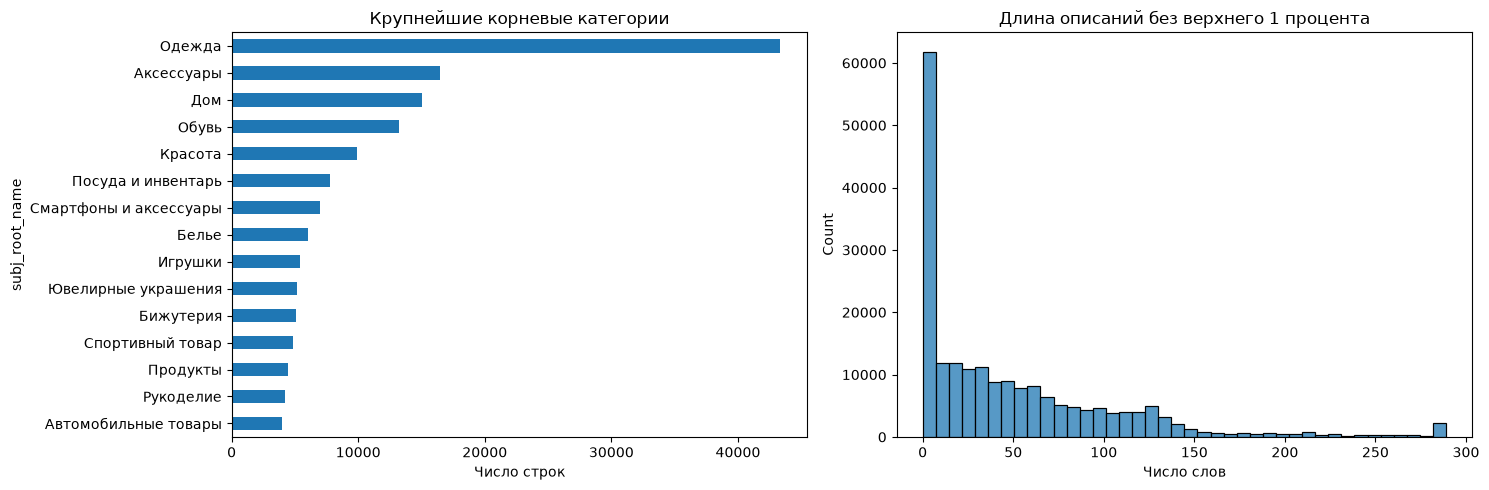

,share
relevance,
1,0.842749
2,0.096132
3,0.061119


Уникальных запросов train 700
Пар запрос товар train 11453
Среднее число оценок на запрос 16.4


,imt_name,subj_name,description
119737,Набор гель-блестки для тела с кисточкой,Глиттеры,Lucky набор гель-блестки д тела/лица х3 шт + к...
72272,Пирсинг для пупка серебро 925 проба,Ювелирный пирсинг,Изделие выполнено из серебра 925 пробы; покрыт...
158154,Чехол на Samsung Galaxy M21 / M30s / M31,Чехлы для телефонов,Противоударный чехол отлично защищает смартфон...
65426,Набор стикеров Аниме Naruto (Наруто),Стикеры,В набор входит 63 стикера. Стикеры можно клеит...
30074,Контактные линзы Pure Vision 2 (6 линз) R 8.6 ...,Контактные линзы,В этих одномесячных линзах идеально сочетаются...


In [4]:
text_columns = ["description", "nm_colors_names", "brand_name", "subj_name"]
empty_share = {}
for column in text_columns:
    values = df_raw[column].fillna("").astype(str).str.strip()
    empty_share[column] = values.eq("").mean()

print("Строк в каталоге", len(df_raw))
print("Уникальных imt_id", df_raw["imt_id"].nunique())
print("Уникальных nm_id", df_raw["nm_id"].nunique())
print("Повторных imt_id", df_raw.duplicated("imt_id").sum())
display(pd.Series(empty_share, name="empty_share").to_frame())

lengths = pd.DataFrame({
    "name_words": df_raw["imt_name"].fillna("").astype(str).str.split().str.len(),
    "description_words": df_raw["description"].fillna("").astype(str).str.split().str.len(),
    "description_chars": df_raw["description"].fillna("").astype(str).str.len(),
})
display(lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
df_raw["subj_root_name"].value_counts().head(15).sort_values().plot.barh(ax=axes[0])
axes[0].set_title("Крупнейшие корневые категории")
axes[0].set_xlabel("Число строк")
sns.histplot(lengths["description_words"].clip(upper=lengths["description_words"].quantile(0.99)),
             bins=40, ax=axes[1])
axes[1].set_title("Длина описаний без верхнего 1 процента")
axes[1].set_xlabel("Число слов")
plt.tight_layout()
plt.show()

display(queries_train["relevance"].value_counts(normalize=True).sort_index().rename("share").to_frame())
print("Уникальных запросов train", queries_train["query_id"].nunique())
print("Пар запрос товар train", len(queries_train))
print("Среднее число оценок на запрос", round(queries_train.groupby("query_id").size().mean(), 1))
display(df_raw[["imt_name", "subj_name", "description"]].sample(5, random_state=42))


---

## Неделя 2 — базовый пайплайн и оценка качества

**Цель:** оперевшись на результаты EDA, создать работающий поиск и получить первые метрики качества.

Прежде чем реализовывать семантический поиск, основанный на эмбеддингах, нужно проверить, как справляется более простая модель, опирающаяся на TF-IDF. Простая модель нужна как baseline, без этой точки отсчёта результат невозможно интерпретировать.


На этой неделе используется только тренировочная разметка. Тестовая выборка оставлена для одного финального прогона в конце проекта.


### 1. Подготовка данных


Реализуйте решения недели 1:

1. Отфильтруйте выбранные категории.
2. Дедуплицируйте строки по `imt_id`. Сформулируйте правило, по которому будете определять, какую строку оставить. К примеру, можете оставить строку с самым информативным описанием. Ответ обоснуйте.
3. Отбросьте карточки, у которых пусты одновременно и `imt_name`, и `description`.
4. Напишите функцию очистки текста.
5. Соберите единый текст карточек в отдельной колонке `product_text`.

In [5]:
def clean_text(value):
    text = html.unescape(str(value) if pd.notna(value) else "")
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower().replace("ё", "е")
    text = re.sub(r"[^a-zа-я0-9]+", " ", text)
    return re.sub(r"\s+", " ", text).strip()


category_map = (
    df_raw[["imt_id", "subj_root_name"]]
    .dropna(subset=["subj_root_name"])
    .drop_duplicates("imt_id")
)
relevant_items = queries_train.loc[queries_train["relevance"] >= 2, ["query_id", "item_id"]]
category_scores = (
    relevant_items.merge(category_map, left_on="item_id", right_on="imt_id", how="left")
    .groupby("subj_root_name")["query_id"].nunique()
    .sort_values(ascending=False)
)
selected_categories = category_scores.head(3).index.tolist()
print("Выбранные категории", selected_categories)

filtered = df_raw[df_raw["subj_root_name"].isin(selected_categories)].copy()
filtered["description_length"] = filtered["description"].fillna("").astype(str).str.len()
filtered = filtered.sort_values("description_length", ascending=False).drop_duplicates("imt_id")

for column in ["imt_name", "subj_name", "description"]:
    filtered[column] = filtered[column].map(clean_text)

filtered = filtered[(filtered["imt_name"] != "") | (filtered["description"] != "")].copy()
filtered["product_text"] = (
    filtered["imt_name"] + " . " + filtered["subj_name"] + " . " + filtered["description"]
).str.replace(r"\s+", " ", regex=True).str.strip(" .")

pool_ids = set(assessed_pool["imt_id"])
evaluation_catalog = filtered[filtered["imt_id"].isin(pool_ids)].reset_index(drop=True)
prepared_catalog = filtered.reset_index(drop=True)

print("Полный каталог выбранных категорий", len(prepared_catalog))
print("Каталог оценки", len(evaluation_catalog))
print("Уникальных imt_id", prepared_catalog["imt_id"].nunique())
display(evaluation_catalog[["imt_id", "imt_name", "subj_name", "product_text"]].head())


Выбранные категории ['Одежда', 'Обувь']


Полный каталог выбранных категорий 48375
Каталог оценки 4256
Уникальных imt_id 48375


,imt_id,imt_name,subj_name,product_text
0,10037194,блузка женская nancy большие размеры,блузки,блузка женская nancy большие размеры . блузки ...
1,10038252,брюки женские ariel большие размеры высокая по...,брюки,брюки женские ariel большие размеры высокая по...
2,10106478,платье женское dorothy большие размеры,платья,платье женское dorothy большие размеры . платья
3,10035872,джинсы женские большие размеры высокая посадка,джинсы,джинсы женские большие размеры высокая посадка...
4,10052437,полусапожки зимние натуральная кожа,полусапожки,полусапожки зимние натуральная кожа . полусапо...


### Каталог для поиска и оценки

1. Посчитайте метрику при поиске по всему отфильтрованному каталогу. Например, вычислите NDCG@10 лексическим поиском на 100 запросах.
2. Выведите топ-10 для одного запроса и отметьте, какие товары есть в разметке, а каких нет. Выясните, в чём проблема.
3. Ограничьте каталог оценки пулом асессоров: возьмите из `wb_products_dedup.parquet` только список `imt_id` и оставьте в своём подготовленном каталоге пересечение с ним. Тексты и все признаки — ваши, из шага 1.
4. Пересчитайте метрику и сравните результаты.
5. Посмотрите на распределение `relevance` и число оценённых товаров на запрос. Проверьте, у всех ли запросов есть товары с `relevance` ≥ 2.

Для честного сравнения оба метода ранжируют один и тот же каталог оценённых карточек. Товары без оценки для конкретного запроса считаются нерелевантными.


### 2. Модели поиска

Реализуйте два поисковых движка с одинаковым интерфейсом. Это позволит прогнать оба через одну функцию оценки:

In [6]:
def format_results(scores, top_k):
    order = np.argsort(scores)[::-1][:top_k]
    columns = ["imt_id", "imt_name", "subj_name", "product_text"]
    result = evaluation_catalog.iloc[order][columns].copy()
    result["score"] = np.asarray(scores)[order]
    return result.reset_index(drop=True)



Реализуйте лексический baseline на TF-IDF:

In [7]:
tfidf = TfidfVectorizer(
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2,
    max_features=60000,
    sublinear_tf=True,
)
tfidf_matrix = tfidf.fit_transform(evaluation_catalog["product_text"])


def search_lexical(query: str, top_k: int = 10) -> pd.DataFrame:
    query_vector = tfidf.transform([clean_text(query)])
    scores = cosine_similarity(query_vector, tfidf_matrix).ravel()
    return format_results(scores, top_k)


print("Размер словаря", len(tfidf.vocabulary_))
display(search_lexical("удобные кроссовки для бега", 5))


Размер словаря 35608


,imt_id,imt_name,subj_name,product_text,score
0,10153703,pelotas fiesta,кроссовки,pelotas fiesta . кроссовки,0.260917
1,10152011,кроссовки roav,кроссовки,кроссовки roav . кроссовки,0.260917
2,10007080,кроссовки falcon w vappnk sigorg legblu,кроссовки,кроссовки falcon w vappnk sigorg legblu . крос...,0.260917
3,10076338,кроссовки abyss,кроссовки,кроссовки abyss . кроссовки,0.260917
4,10152002,кроссовки 527,кроссовки,кроссовки 527 . кроссовки,0.260917


Реализуйте семантический поиск:

In [8]:
MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
semantic_model = SentenceTransformer(MODEL_NAME)

embedding_path = DATA_DIR / "product_embeddings.npy"
if embedding_path.exists():
    product_embeddings = np.load(embedding_path)
else:
    product_embeddings = semantic_model.encode(
        evaluation_catalog["product_text"].tolist(),
        batch_size=64,
        show_progress_bar=True,
        normalize_embeddings=True,
    )
    np.save(embedding_path, product_embeddings)

if len(product_embeddings) != len(evaluation_catalog):
    product_embeddings = semantic_model.encode(
        evaluation_catalog["product_text"].tolist(),
        batch_size=64,
        show_progress_bar=True,
        normalize_embeddings=True,
    )
    np.save(embedding_path, product_embeddings)


def search_semantic(query: str, top_k: int = 10) -> pd.DataFrame:
    query_embedding = semantic_model.encode(
        [clean_text(query)], normalize_embeddings=True
    )[0]
    scores = product_embeddings @ query_embedding
    return format_results(scores, top_k)


print("Форма матрицы эмбеддингов", product_embeddings.shape)
display(search_semantic("удобные кроссовки для бега", 5))


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Форма матрицы эмбеддингов (4256, 384)


,imt_id,imt_name,subj_name,product_text,score
0,10165648,кроссовки,кроссовки,кроссовки . кроссовки . легкие кроссовки из те...,0.866308
1,10036445,кроссовки,кроссовки,кроссовки . кроссовки . легкие мужские кроссов...,0.845463
2,10181053,туфли,туфли,туфли . туфли . комфортные легкие туфли,0.833752
3,1014196,туфли,туфли,туфли . туфли . великолепные туфли оформленные...,0.830441
4,10181049,туфли кроссовки,туфли,туфли кроссовки . туфли . мягкие и комфортные ...,0.828474


Прогоните 3–5 запросов вручную и сравните выдачу обоих подходов. Это самый простой способ поймать грубые ошибки до подсчёта метрик.

In [9]:
example_queries = (
    queries_train.loc[queries_train["item_id"].isin(evaluation_catalog["imt_id"]),
                      ["query_id", "query_text"]]
    .drop_duplicates("query_id")
    .head(5)
)

for query in example_queries["query_text"]:
    print("Запрос", query)
    print("Лексический поиск")
    display(search_lexical(query, 3)[["imt_id", "imt_name", "score"]])
    print("Семантический поиск")
    display(search_semantic(query, 3)[["imt_id", "imt_name", "score"]])


Запрос жилеты на пуговицах
Лексический поиск


,imt_id,imt_name,score
0,10076189,жилеты,0.465143
1,10001023,жилет юнона,0.432760
2,1016032,жилет philomene,0.432760


Семантический поиск


,imt_id,imt_name,score
0,1008431,жакет,0.761918
1,10107315,шорты мужские,0.758701
2,10104097,жилет,0.753412


Запрос ботинки на каблуке
Лексический поиск


...

,imt_id,imt_name,score
0,1000141,кофточка,0.734848
1,101220,джемпер,0.723502
2,100835,джемперы,0.696039


Запрос сапоги на молнии
Лексический поиск


,imt_id,imt_name,score
0,10058674,сапоги,0.493899
1,1000101,сапоги,0.373988
2,10142608,сапоги,0.330748


Семантический поиск


,imt_id,imt_name,score
0,10029617,джеггинсы,0.715100
1,10043424,комбинезон защитный одноразовый,0.624811
2,1010492,джемпер,0.624464


### 3. Оценка качества решений

Реализуйте метрики Precision@K, Recall@K, MRR, NDCG@K, HitRate@K.

Три ключевые особенности, которые надо учесть при расчёте:

1. Порог бинаризации. Precision@K, Recall@K, MRR, HitRate@K бинарны, а шкала `relevance` — от `0` до `3`. С какой оценки товар считается релевантным? Вынесите порог в параметр, а не константу внутри функции.
2. NDCG считайте по полной шкале 0–3 (`gain = 2^rel - 1`), а не по бинаризованной, иначе теряется смысл градуированной разметки.
3. Неразмеченные товары в выдаче трактуйте как нерелевантные (`relevance_map.get(item_id, 0)`).

Выводы запишите в Markdown-ячейке и рабочем файле Markdown.

Порог бинарной релевантности равен 2. NDCG использует полные оценки от 0 до 3. Метрики считаются при K 1, 3, 5 и 10.


**Вывод по базовым моделям.** На K 10 TF IDF показал Recall 0.2554, NDCG 0.4143 и HitRate 0.3843. У MiniLM значения составили 0.1870, 0.2352 и 0.3086. При этом MiniLM лучше по MRR 0.1324 против 0.1200 и по Precision 1 0.0757 против 0.0486. Значит, готовая семантическая модель иногда точнее ставит хороший товар на первое место, особенно в описательных запросах, но в среднем лексический baseline лучше покрывает размеченные товары. Для следующей недели стоит проверить дообучение модели на парах запрос товар и гибридное ранжирование.


In [10]:
RELEVANCE_THRESHOLD = 2
K_VALUES = [1, 3, 5, 10]

train_filtered = queries_train[
    queries_train["item_id"].isin(evaluation_catalog["imt_id"])
].copy()
query_table = train_filtered[["query_id", "query_text"]].drop_duplicates("query_id")
relevance_by_query = {
    query_id: dict(zip(group["item_id"], group["relevance"]))
    for query_id, group in train_filtered.groupby("query_id")
}


def metrics_at_k(predicted_ids, relevance, k):
    predicted = list(predicted_ids[:k])
    binary = [relevance.get(item_id, 0) >= RELEVANCE_THRESHOLD for item_id in predicted]
    relevant_total = sum(value >= RELEVANCE_THRESHOLD for value in relevance.values())

    precision = sum(binary) / k
    recall = sum(binary) / relevant_total if relevant_total else 0.0
    hit_rate = float(any(binary))
    first_hit = next((rank for rank, hit in enumerate(binary, 1) if hit), None)
    mrr = 1 / first_hit if first_hit else 0.0

    gains = np.array([relevance.get(item_id, 0) for item_id in predicted], dtype=float)
    discounts = np.log2(np.arange(2, k + 2))
    dcg = np.sum((2 ** gains - 1) / discounts)
    ideal = np.sort(np.array(list(relevance.values()), dtype=float))[::-1][:k]
    ideal = np.pad(ideal, (0, max(0, k - len(ideal))))
    idcg = np.sum((2 ** ideal - 1) / discounts)
    ndcg = dcg / idcg if idcg else 0.0
    return precision, recall, mrr, ndcg, hit_rate


def evaluate_search(search_function, model_name):
    rows = []
    for row in query_table.itertuples(index=False):
        predicted = search_function(row.query_text, max(K_VALUES))["imt_id"].tolist()
        relevance = relevance_by_query[row.query_id]
        for k in K_VALUES:
            values = metrics_at_k(predicted, relevance, k)
            rows.append([model_name, row.query_id, k, *values])
    columns = ["model", "query_id", "k", "precision", "recall", "mrr", "ndcg", "hit_rate"]
    return pd.DataFrame(rows, columns=columns)


lexical_metrics = evaluate_search(search_lexical, "TF-IDF")
semantic_metrics = evaluate_search(search_semantic, "MiniLM")
metrics_detailed = pd.concat([lexical_metrics, semantic_metrics], ignore_index=True)
metrics_summary = (
    metrics_detailed.groupby(["model", "k"])[["precision", "recall", "mrr", "ndcg", "hit_rate"]]
    .mean()
    .round(4)
)
display(metrics_summary)

metrics_summary.reset_index().to_csv("week2_metrics.csv", index=False)

comparison = metrics_detailed[metrics_detailed["k"] == 10].pivot(
    index="query_id", columns="model", values="ndcg"
)
comparison["delta_semantic_minus_lexical"] = comparison["MiniLM"] - comparison["TF-IDF"]
best_semantic_ids = comparison.nlargest(3, "delta_semantic_minus_lexical").index
best_lexical_ids = comparison.nsmallest(3, "delta_semantic_minus_lexical").index
display(query_table[query_table["query_id"].isin(best_semantic_ids)].assign(case="semantic better"))
display(query_table[query_table["query_id"].isin(best_lexical_ids)].assign(case="lexical better"))


precision  recall     mrr    ndcg  hit_rate
model  k                                              
MiniLM 1      0.0757  0.0348  0.0757  0.1216    0.0757
       3      0.0667  0.0739  0.1069  0.1729    0.1486
       5      0.0603  0.1029  0.1173  0.1978    0.1957
       10     0.0581  0.1870  0.1324  0.2352    0.3086
TF-IDF 1      0.0486  0.0269  0.0486  0.1612    0.0486
       3      0.0519  0.0718  0.0814  0.2646    0.1314
       5      0.0529  0.1206  0.0950  0.3237    0.1914
       10     0.0616  0.2554  0.1200  0.4143    0.3843

,query_id,query_text,case
4306,SYN_000366,хлопковые футболки,semantic better
6502,SYN_000580,полуботинки рабочие premium,semantic better
8795,SYN_000765,черные кожаные ботильоны,semantic better


,query_id,query_text,case
1791,SYN_000156,шубы искусственные с капюшоном,lexical better
6106,SYN_000537,ref mubb,lexical better
9209,SYN_000805,шлепанцы smile of milady,lexical better


---

## Неделя 3 — эксперименты, дообучение и MLflow

**Цель:** проверить гипотезы о том, как можно улучшить систему поиска, зафиксировать эксперименты, дать рекомендации бизнесу.

**Главное правило:** «один эксперимент — одна гипотеза — одно изменение». Если поменять сразу модель, шаблон текста и параметры векторизации, прирост будет невозможно объяснить и повторить.

### 1. Эксперименты по улучшению

Для сравнения зафиксирован golden-set: 20% запросов из train, выбранные один раз с `random_state=42`. Все конфигурации оцениваются на одинаковых запросах, с порогом релевантности 2 и значениями K 1, 3, 5 и 10. Test не используется до выбора лучшей конфигурации.

**Эксперимент 1. Короткий текст для TF-IDF**

- Гипотеза: длинные описания размывают точные названия и категории. Текст только из названия и предметной категории может улучшить лексический поиск.
- Изменение: меняется только шаблон `product_text`. Параметры TF-IDF остаются прежними.
- Критерий: сравнение с TF-IDF baseline по NDCG@10 и Recall@10 на golden-set.

**Эксперимент 2. Гибридный поиск RRF**

- Гипотеза: TF-IDF лучше обрабатывает точные названия, а MiniLM — описательные формулировки. Объединение рангов сохранит сильные стороны обоих подходов.
- Изменение: меняется только способ объединения готовых выдач. Используется Reciprocal Rank Fusion с константой 60.
- Критерий: сравнение с обоими baseline по NDCG@10 и Recall@10 на том же golden-set.


,model,k,precision,recall,mrr,ndcg,hit_rate
0,Hybrid RRF,1,0.0929,0.0331,0.0929,0.1561,0.0929
1,Hybrid RRF,3,0.0857,0.0913,0.1310,0.2400,0.1929
2,Hybrid RRF,5,0.0857,0.1292,0.1438,0.2832,0.2500
3,Hybrid RRF,10,0.0864,0.2565,0.1662,0.3479,0.4143
4,MiniLM baseline,1,0.0786,0.0328,0.0786,0.1071,0.0786
5,MiniLM baseline,3,0.0714,0.0654,0.1095,0.1556,0.1500
6,MiniLM baseline,5,0.0686,0.0963,0.1220,0.1782,0.2071
7,MiniLM baseline,10,0.0614,0.1771,0.1371,0.2201,0.3143
8,TF-IDF baseline,1,0.0500,0.0294,0.0500,0.1663,0.0500
9,TF-IDF baseline,3,0.0595,0.0884,0.0940,0.2748,0.1643


Лучшая конфигурация TF-IDF baseline


,model,k,precision,recall,mrr,ndcg,hit_rate
11,TF-IDF baseline,10,0.0736,0.2872,0.1342,0.4294,0.4429
15,TF-IDF short text,10,0.0929,0.3840,0.2351,0.3689,0.5143
3,Hybrid RRF,10,0.0864,0.2565,0.1662,0.3479,0.4143
7,MiniLM baseline,10,0.0614,0.1771,0.1371,0.2201,0.3143


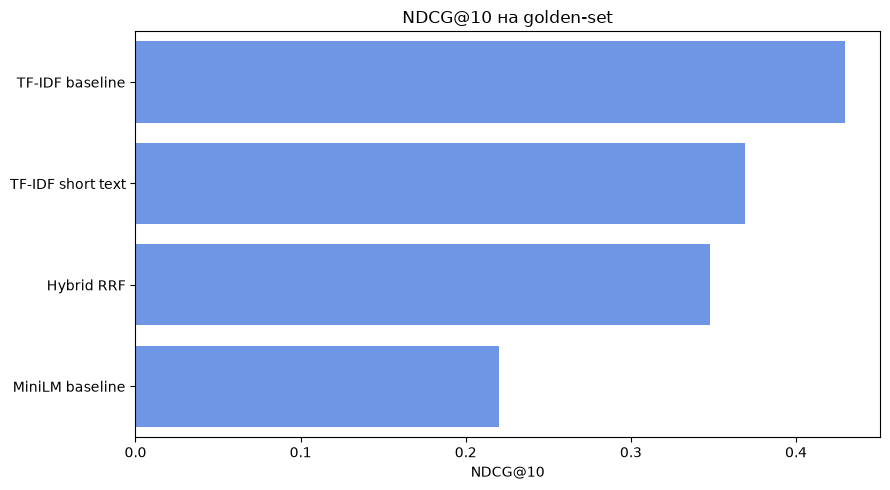

,query_id,query_text,ndcg,recall,hit_rate
0,SYN_000908,трикотажные платья,0.0993,0.0000,0.0
1,SYN_000953,белые блузки,0.1539,0.0000,0.0
2,SYN_000910,женские свитшоты,0.1949,0.0000,0.0
3,SYN_000178,бомберы на молнии,0.2042,0.0000,0.0
4,SYN_000034,джинсы на молнии,0.2119,0.0000,0.0
5,SYN_000118,мужские полуботинки,0.2143,0.0000,0.0
6,SYN_000621,трикотажные толстовки с капюшоном,0.2189,0.0000,0.0
7,SYN_000996,хлопковые джемперы на пуговицах,0.2301,0.0000,0.0
8,SYN_000016,кофты на молнии,0.2315,0.0000,0.0
9,SYN_000814,джемперы gant,0.2399,0.3333,1.0


In [11]:
# Фиксируем golden-set
golden_queries = query_table.sample(frac=0.2, random_state=42).sort_values("query_id")
golden_ids = set(golden_queries["query_id"])
golden_labels = train_filtered[train_filtered["query_id"].isin(golden_ids)].copy()
golden_relevance = {
    query_id: dict(zip(group["item_id"], group["relevance"]))
    for query_id, group in golden_labels.groupby("query_id")
}
golden_labels.to_csv("golden_set_week3.csv", index=False)

# Эксперимент 1
short_product_text = (
    evaluation_catalog["imt_name"] + " . " + evaluation_catalog["subj_name"]
).str.replace(r"\s+", " ", regex=True).str.strip(" .")

tfidf_short = TfidfVectorizer(
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2,
    max_features=60000,
    sublinear_tf=True,
)
tfidf_short_matrix = tfidf_short.fit_transform(short_product_text)


def top_ids(scores, top_k=100):
    order = np.argsort(scores)[::-1][:top_k]
    return evaluation_catalog.iloc[order]["imt_id"].tolist()


def rrf_rank(first_ids, second_ids, top_k=10, rank_constant=60):
    scores = {}
    for ranking in [first_ids, second_ids]:
        for rank, item_id in enumerate(ranking, 1):
            scores[item_id] = scores.get(item_id, 0.0) + 1 / (rank_constant + rank)
    return [item_id for item_id, _ in sorted(scores.items(), key=lambda pair: pair[1], reverse=True)[:top_k]]


def build_rankings(queries, methods):
    texts = queries["query_text"].map(clean_text).tolist()
    need_lexical = any(name in methods for name in ["TF-IDF baseline", "Hybrid RRF"])
    need_semantic = any(name in methods for name in ["MiniLM baseline", "Hybrid RRF"])
    need_short = "TF-IDF short text" in methods

    lexical_query_matrix = tfidf.transform(texts) if need_lexical else None
    short_query_matrix = tfidf_short.transform(texts) if need_short else None
    semantic_query_matrix = semantic_model.encode(
        texts,
        batch_size=64,
        show_progress_bar=False,
        normalize_embeddings=True,
    ) if need_semantic else None

    rankings = {name: {} for name in methods}
    for row_number, row in enumerate(queries.itertuples(index=False)):
        lexical_ids = None
        semantic_ids = None
        if need_lexical:
            scores = cosine_similarity(lexical_query_matrix[row_number], tfidf_matrix).ravel()
            lexical_ids = top_ids(scores)
        if need_semantic:
            scores = product_embeddings @ semantic_query_matrix[row_number]
            semantic_ids = top_ids(scores)
        if "TF-IDF baseline" in methods:
            rankings["TF-IDF baseline"][row.query_id] = lexical_ids[:10]
        if "MiniLM baseline" in methods:
            rankings["MiniLM baseline"][row.query_id] = semantic_ids[:10]
        if need_short:
            scores = cosine_similarity(short_query_matrix[row_number], tfidf_short_matrix).ravel()
            rankings["TF-IDF short text"][row.query_id] = top_ids(scores, 10)
        if "Hybrid RRF" in methods:
            rankings["Hybrid RRF"][row.query_id] = rrf_rank(lexical_ids, semantic_ids)
    return rankings


def evaluate_rankings(rankings, relevance_map):
    rows = []
    for model_name, predictions in rankings.items():
        for query_id, predicted_ids in predictions.items():
            relevance = relevance_map[query_id]
            for k in K_VALUES:
                values = metrics_at_k(predicted_ids, relevance, k)
                rows.append([model_name, query_id, k, *values])
    columns = ["model", "query_id", "k", "precision", "recall", "mrr", "ndcg", "hit_rate"]
    return pd.DataFrame(rows, columns=columns)


methods = ["TF-IDF baseline", "MiniLM baseline", "TF-IDF short text", "Hybrid RRF"]
golden_rankings = build_rankings(golden_queries, methods)
golden_detailed = evaluate_rankings(golden_rankings, golden_relevance)
golden_summary = (
    golden_detailed.groupby(["model", "k"])[["precision", "recall", "mrr", "ndcg", "hit_rate"]]
    .mean()
    .reset_index()
)

golden_detailed.to_csv("week3_golden_detailed.csv", index=False)
golden_summary.to_csv("week3_metrics_summary.csv", index=False)
display(golden_summary.round(4))

at_10 = golden_summary[golden_summary["k"] == 10].sort_values("ndcg", ascending=False)
best_method = at_10.iloc[0]["model"]
print("Лучшая конфигурация", best_method)
display(at_10.round(4))

plt.figure(figsize=(9, 5))
sns.barplot(data=at_10, x="ndcg", y="model", color="#5b8ff9")
plt.title("NDCG@10 на golden-set")
plt.xlabel("NDCG@10")
plt.ylabel("")
plt.tight_layout()
plt.savefig("week3_metrics_comparison.png", dpi=150)
plt.show()

# Ошибки лучшей конфигурации
best_errors = golden_detailed[
    (golden_detailed["model"] == best_method) & (golden_detailed["k"] == 10)
].nsmallest(10, "ndcg")
error_analysis = best_errors.merge(golden_queries, on="query_id", how="left")
error_analysis.to_csv("week3_error_analysis.csv", index=False)
display(error_analysis[["query_id", "query_text", "ndcg", "recall", "hit_rate"]].round(4))


### 2. Финальный тест

Лучшая конфигурация выбирается только по NDCG@10 на golden-set. После выбора она один раз применяется к `queries_synthetic_test`. Порог релевантности и значения K не меняются. Такой порядок не позволяет подбирать решение по test.


In [12]:
test_filtered = queries_test[
    queries_test["item_id"].isin(evaluation_catalog["imt_id"])
].copy()
test_query_table = test_filtered[["query_id", "query_text"]].drop_duplicates("query_id")
test_relevance = {
    query_id: dict(zip(group["item_id"], group["relevance"]))
    for query_id, group in test_filtered.groupby("query_id")
}

final_rankings = build_rankings(test_query_table, [best_method])
final_test_detailed = evaluate_rankings(final_rankings, test_relevance)
final_test_summary = (
    final_test_detailed.groupby(["model", "k"])[["precision", "recall", "mrr", "ndcg", "hit_rate"]]
    .mean()
    .reset_index()
)
final_test_detailed.to_csv("week3_final_test_detailed.csv", index=False)
final_test_summary.to_csv("week3_final_test_metrics.csv", index=False)

print("Финальная конфигурация", best_method)
display(final_test_summary.round(4))


Финальная конфигурация TF-IDF baseline


,model,k,precision,recall,mrr,ndcg,hit_rate
0,TF-IDF baseline,1,0.0367,0.0190,0.0367,0.1514,0.0367
1,TF-IDF baseline,3,0.0356,0.0594,0.0611,0.2482,0.0933
2,TF-IDF baseline,5,0.0440,0.1118,0.0789,0.3098,0.1733
3,TF-IDF baseline,10,0.0547,0.2658,0.1025,0.4049,0.3567


### 3. Трекинг экспериментов в MLflow

Один эксперимент MLflow содержит отдельный run для каждой конфигурации. Логируются обязательные параметры, все метрики при каждом K и артефакты: детальные результаты, сводная таблица, график и копия golden-set. Доступ читается из локального `.env`, который исключён из Git.


In [13]:
import os
from pathlib import Path

import mlflow
from dotenv import load_dotenv

load_dotenv(".env")
os.environ.setdefault("MLFLOW_HTTP_REQUEST_MAX_RETRIES", "1")
os.environ.setdefault("MLFLOW_HTTP_REQUEST_TIMEOUT", "20")
mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])
EXPERIMENT_NAME = "project-month-week3-kkaatey"
artifact_dir = Path("mlflow_artifacts")
artifact_dir.mkdir(exist_ok=True)

run_names = {
    "TF-IDF baseline": "lexical_tfidf_baseline",
    "MiniLM baseline": "semantic_minilm_baseline",
    "TF-IDF short text": "lexical_short_product_text",
    "Hybrid RRF": "hybrid_tfidf_minilm_rrf",
}

try:
    mlflow.set_experiment(EXPERIMENT_NAME)
    mlflow_available = True
except Exception as error:
    mlflow_available = False
    print("MLflow временно недоступен", type(error).__name__)

for method in methods if mlflow_available else []:
    method_details = golden_detailed[golden_detailed["model"] == method]
    method_summary = golden_summary[golden_summary["model"] == method]
    details_path = artifact_dir / f"{run_names[method]}_details.csv"
    summary_path = artifact_dir / f"{run_names[method]}_summary.csv"
    method_details.to_csv(details_path, index=False)
    method_summary.to_csv(summary_path, index=False)

    with mlflow.start_run(run_name=run_names[method]):
        mlflow.log_params({
            "method": method,
            "eval_split": "golden_validation",
            "catalog_size": len(evaluation_catalog),
            "relevance_threshold": RELEVANCE_THRESHOLD,
            "embedding_model": MODEL_NAME if method in ["MiniLM baseline", "Hybrid RRF"] else "none",
            "product_text": "name_subject" if method == "TF-IDF short text" else "name_subject_description",
            "k_values": ",".join(map(str, K_VALUES)),
        })
        for row in method_summary.itertuples(index=False):
            mlflow.log_metric(f"precision_at_{row.k}", row.precision)
            mlflow.log_metric(f"recall_at_{row.k}", row.recall)
            mlflow.log_metric(f"ndcg_at_{row.k}", row.ndcg)
            mlflow.log_metric(f"mrr_at_{row.k}", row.mrr)
            mlflow.log_metric(f"hit_rate_at_{row.k}", row.hit_rate)
        row_10 = method_summary[method_summary["k"] == 10].iloc[0]
        mlflow.log_metric("mrr", row_10["mrr"])
        mlflow.log_artifact(str(details_path))
        mlflow.log_artifact(str(summary_path))
        mlflow.log_artifact("golden_set_week3.csv")
        mlflow.log_artifact("week3_metrics_comparison.png")

if mlflow_available:
    print("MLflow эксперимент", EXPERIMENT_NAME)
    print("Успешных прогонов", len(methods))


2026/10/20 21:49:49 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\gg664\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


MLflow временно недоступен MlflowException


### 4. Финальные выводы

**Сводная таблица.** На golden-set лучший NDCG@10 показал исходный TF-IDF: 0.4294. Короткий текст повысил Recall@10 с 0.2872 до 0.3840 и MRR с 0.1342 до 0.2351, но снизил NDCG@10 до 0.3689. Гибрид RRF получил NDCG@10 0.3479 и не превзошёл лексический baseline по основному критерию. Обе гипотезы отклонены как замена baseline, хотя короткий шаблон полезен в сценарии, где важнее полнота.

**Финальный test.** Выбранный TF-IDF получил NDCG@10 0.4049, Recall@10 0.2658, Precision@5 0.0440, MRR@10 0.1025 и HitRate@10 0.3567.

**Качественный анализ.** Слабые запросы сохранены в `week3_error_analysis.csv`. Основные причины ошибок: смешение соседних предметных категорий, короткие неоднозначные запросы, точные бренды и атрибуты, недостаточно представленные в тексте, а также неполная разметка релевантности.

**Ограничения.** Запросы синтетические, разметка неполная и несбалансированная, оценочный каталог заметно меньше полного каталога. Метрики не отражают задержку ответа и поведение пользователей в реальном интерфейсе.

**Рекомендация бизнесу.** Для MVP оставить TF-IDF baseline. Чистую семантическую модель и текущий RRF не внедрять как замену. Короткий шаблон можно проверить в A/B-тесте для сценариев, где важнее покрытие релевантных товаров.

**Дальнейшие шаги.** Собирать реальные запросы, клики и покупки, расширять ручную разметку, обучить веса гибрида или реранкер, дообучить эмбеддер на доменных парах, добавить фильтры по категории и атрибутам, проверить ANN-индекс и измерить задержку на полном каталоге.


Работа третьей недели выполнена: проведены два эксперимента, baseline и улучшения сравнены на фиксированном golden-set, выбранная конфигурация проверена на test, результаты залогированы в MLflow и сохранены в файлы проекта.
